In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

In [56]:
df = pd.read_csv("student_sleep_screen_time_academic_performance.csv")
df

,student_id,age,gender,year_of_study,major_category,residence_type,chronotype,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,...,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,has_part_time_job,semester_type,cgpa
0,STU2001,21,Male,3,Humanities,With Family,Early Bird,22.3,7.6,2.0,...,0,10.0,7,5.0,7.0,15.6,80.0,No,Spring,2.99
1,STU2002,20,Female,2,STEM,Dormitory,Intermediate,23.1,5.9,2.7,...,3,7.0,3,6.0,7.0,17.5,78.9,No,Summer,2.88
2,STU2003,20,Male,4,Social Sciences,With Family,Intermediate,23.4,8.4,1.8,...,1,9.0,2,5.0,1.0,19.0,69.7,Yes,Spring,3.15
3,STU2004,22,F,1,Humanities,Off-campus Apartment,Night Owl,0.9,5.1,2.4,...,3,6.0,4,3.0,7.0,7.3,59.1,No,Fall,2.27
4,STU2005,23,Female,4,Social Sciences,Off-campus Apartment,Early Bird,23.4,5.9,2.0,...,2,7.0,6,8.0,3.0,23.6,79.9,No,Summer,2.74
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,STU2496,18,Male,4,Humanities,Dormitory,Intermediate,22.5,7.5,0.4,...,0,8.0,4,7.0,4.0,10.1,90.8,No,Fall,3.21
496,STU2497,22,Male,2,Health Sciences,Dormitory,Night Owl,0.8,6.2,2.4,...,2,10.0,4,6.0,5.0,17.2,70.7,No,Spring,2.87
497,STU2498,20,Female,5,Health Sciences,With Family,Early Bird,22.0,7.1,1.1,...,3,10.0,1,8.0,2.0,21.7,79.8,No,Spring,3.54
498,STU2499,22,M,3,STEM,Dormitory,Early Bird,23.6,9.0,2.3,...,0,10.0,7,7.0,1.0,19.3,97.8,Yes,Spring,3.67


In [57]:
#tempo padrão de sono em dia da semana de alunos
df["avg_sleep_hours_weekday"].value_counts()

avg_sleep_hours_weekday
5.7     19
6.4     19
6.7     18
7.9     18
6.1     17
        ..
9.4      1
2.7      1
10.5     1
3.6      1
9.9      1
Name: count, Length: 70, dtype: int64

In [58]:
#espaço amostral do tempo padrão dos estudadentes com qualidade de sono menor ou igual 6
amostral = df["sleep_quality_score"] <= 6.0
df["avg_sleep_hours_weekday"][amostral].value_counts()

avg_sleep_hours_weekday
5.7    14
6.0     9
5.2     7
5.0     7
6.1     6
6.3     6
4.9     6
5.3     6
5.9     5
5.6     5
6.6     5
6.7     5
5.1     4
4.0     4
7.1     4
3.7     4
5.5     4
6.4     4
4.5     3
4.2     3
7.3     3
6.8     3
6.2     3
4.4     3
3.4     3
6.5     3
3.2     3
4.7     3
4.6     3
4.1     3
3.8     2
7.5     2
3.9     2
4.3     2
5.4     2
8.5     1
5.8     1
7.9     1
2.9     1
3.1     1
7.0     1
7.7     1
3.3     1
4.8     1
2.5     1
7.4     1
8.4     1
2.7     1
3.6     1
7.6     1
Name: count, dtype: int64

In [59]:
#média do tempo padrão de sono
df["avg_sleep_hours_weekday"].mean()

np.float64(6.608199999999999)

In [60]:
#mediana do tempo padrão de sono
df["avg_sleep_hours_weekday"].median()

np.float64(6.6)

In [61]:
#moda do tempo padrão de sono
df["avg_sleep_hours_weekday"].mode()

0    5.7
1    6.4
Name: avg_sleep_hours_weekday, dtype: float64

In [62]:
#desvio padrão do tempo padrão de sono
df_std = df["avg_sleep_hours_weekday"].std()
df_std

np.float64(1.4357840058389164)

In [63]:
#variância do tempo padrão de sono
df_var = df["avg_sleep_hours_weekday"].var()
df_var

np.float64(2.0614757114228452)

In [64]:
#percentil do tempo padrão de sono de 1, 5, 50 e 100
print(np.percentile(df["avg_sleep_hours_weekday"], 1), np.percentile(df["avg_sleep_hours_weekday"], 5), 
      np.percentile(df["avg_sleep_hours_weekday"], 50), np.percentile(df["avg_sleep_hours_weekday"], 100))

3.1990000000000003 4.095 6.6 10.5


In [156]:
#espaço amostral com valores que iremos testar
df2 = df[['avg_sleep_hours_weekday', 'sleep_quality_score', 'concentration_difficulty']]
df2

,avg_sleep_hours_weekday,sleep_quality_score,concentration_difficulty
0,7.6,10.0,7.0
1,5.9,7.0,7.0
2,8.4,9.0,1.0
3,5.1,6.0,7.0
4,5.9,7.0,3.0
...,...,...,...
495,7.5,8.0,4.0
496,6.2,10.0,5.0
497,7.1,10.0,2.0
498,9.0,10.0,1.0


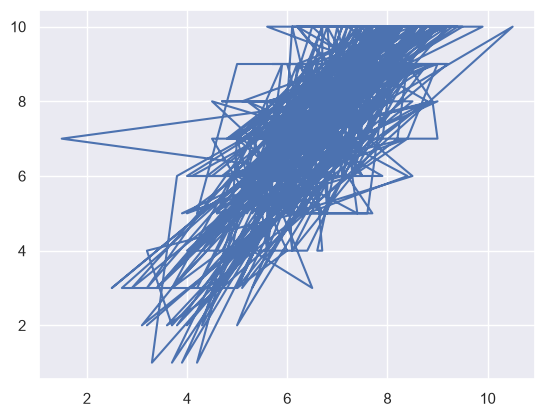

In [152]:
#embora esse seja um grafico de linhas bem bagunçado, podemos ver que alunos com mais horas dormidas tem mais qualidade de sono
plt.plot(df2["avg_sleep_hours_weekday"], df2["sleep_quality_score"])
plt.show()

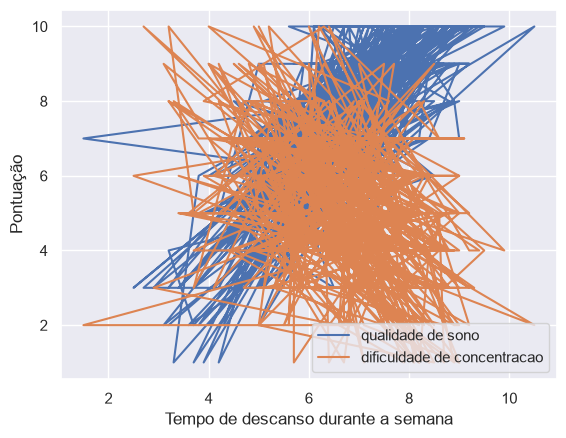

In [153]:
#podemos ver aqui que a dificuldade de concentração diminui conforme o tempo de descanso aumenta
plt.plot(df2["avg_sleep_hours_weekday"], df2["sleep_quality_score"])
plt.plot(df2["avg_sleep_hours_weekday"], df2["concentration_difficulty"])
plt.xlabel("Tempo de descanso durante a semana")
plt.ylabel("Pontuação")
plt.legend(['qualidade de sono', 'dificuldade de concentracao'], loc=4)
plt.show()

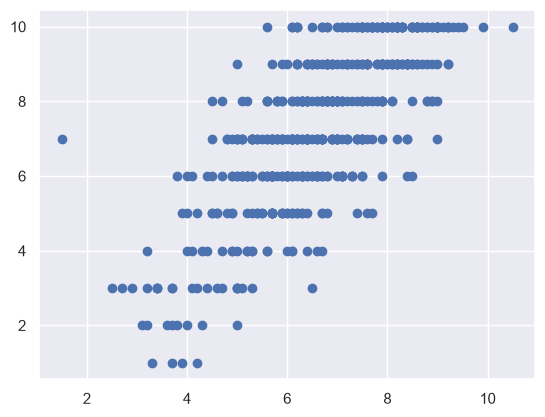

In [154]:
#mesmo gráfico que o primeiro, mas com gráfico scatter
plt.scatter(df2["avg_sleep_hours_weekday"], df2["sleep_quality_score"])
plt.show()

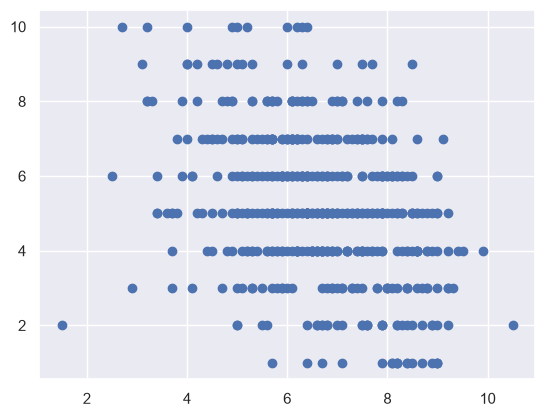

In [155]:
#mesmo gráfico que o segundo, mas com gráfico scatter
plt.scatter(df2["avg_sleep_hours_weekday"], df2["concentration_difficulty"])
plt.show()

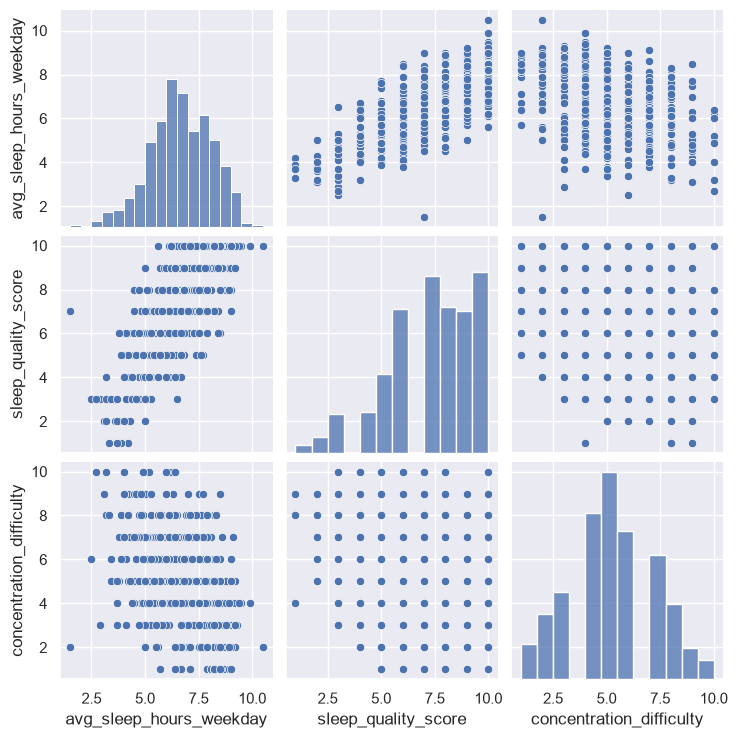

In [72]:
#graficos comparando os 3
sns.pairplot(df2, height=2.5);
plt.show()

In [73]:
#Momentos do primeiro ao ultimo das colunas escolhidas na df2
df2.mean()

avg_sleep_hours_weekday     6.608200
sleep_quality_score         7.271255
concentration_difficulty    5.176955
dtype: float64

In [74]:
df2.var()

avg_sleep_hours_weekday     2.061476
sleep_quality_score         4.542904
concentration_difficulty    4.133571
dtype: float64

In [75]:
df2.skew()

avg_sleep_hours_weekday    -0.284176
sleep_quality_score        -0.589449
concentration_difficulty    0.082046
dtype: float64

In [76]:
df2.kurt()

avg_sleep_hours_weekday    -0.088818
sleep_quality_score        -0.188377
concentration_difficulty   -0.335313
dtype: float64

In [89]:
#covariancia do tempo de sono e qualidade de sono
np.cov(df2['avg_sleep_hours_weekday'], df2['sleep_quality_score'])
#o resultado deu 2, o que significa que existe uma correlação, mas nn se pode dizer se um causa o outro 

array([[2.06147571,        nan],
       [       nan,        nan]])

In [80]:
#covariancia do tempo de sono e dificuldade de concentração
np.cov(df2['avg_sleep_hours_weekday'], df2['concentration_difficulty'])
#o resultado deu 2, o que significa que existe uma correlação, mas nn se pode dizer se um causa o outro

array([[2.06147571,        nan],
       [       nan,        nan]])

In [83]:
#covariancia da qualidade de sono e dificuldade de concentração
np.cov(df2['concentration_difficulty'], df2['sleep_quality_score'])
#como pode ver, dificuldade de concentração não tem correlação com a qualidade de sono

array([[nan, nan],
       [nan, nan]])

In [81]:
#correlação entre o tempo de sono e a qualidade de sono
np.corrcoef(df2['avg_sleep_hours_weekday'], df2['sleep_quality_score'])
#correlação perfeita (se um aumenta, o outro aumenta)

array([[ 1., nan],
       [nan, nan]])

In [82]:
#correlação entre o tempo de sono e a dificuldade de concentração
np.corrcoef(df2['avg_sleep_hours_weekday'], df2['concentration_difficulty'])
#correlação perfeita

array([[ 1., nan],
       [nan, nan]])

In [84]:
#correlação entre a qualidade de sono e a dificuldade de concentração
np.corrcoef(df2['sleep_quality_score'], df2['concentration_difficulty'])
#nenhuma correlação

array([[nan, nan],
       [nan, nan]])

In [125]:
#P(A) = pessoas com menos de 5.5 horas de sono
condA = df2["avg_sleep_hours_weekday"] < 5.5
Prob_A = df2["avg_sleep_hours_weekday"][condA].count() / len(df2)
#20% das pessoas
Prob_A * 100

np.float64(20.200000000000003)

In [126]:
#P(B) = pessoas com a qualidade de sono menor que 5.5
condB = df2["sleep_quality_score"] < 5.5
Prob_B = df2["sleep_quality_score"][condB].count() / len(df2)
#18%
Prob_B * 100

np.float64(18.6)

In [141]:
#P(A intersecção B)
ProbAinterB = df2["avg_sleep_hours_weekday"][condA & condB].count() / len(df2)
#11%
ProbAinterB * 100

np.float64(11.600000000000001)

In [140]:
#P(A|B) = probabilidade de A após B
ProbA_B = ProbAinterB / Prob_B
#62%, logo, A depende de B(62% != 20%)
ProbA_B * 100

np.float64(20.200000000000003)

In [146]:
#P(A,B) = probabilidade de ambos ocorrerem
Prob_AB = Prob_A + Prob_B - ProbAinterB
#27%
Prob_AB*100

np.float64(27.200000000000003)

In [132]:
#P(C) = probabilidade da dificuldade de concentração estar menor que 5.5
condC = df2["concentration_difficulty"] < 5.5
Prob_C = df2["concentration_difficulty"][condC].count() / len(df2)
#56%
Prob_C * 100

np.float64(56.8)

In [142]:
#P(A intersecção C)
ProbAinterC = df2["avg_sleep_hours_weekday"][condA & condC].count() / len(df2)
#8%
ProbAinterC * 100

np.float64(8.4)

In [143]:
#P(A|C) = probabilidade de A após C
ProbA_C = ProbAinterC / Prob_C
#20%, logo A é dependente de C
ProbA_C * 100

np.float64(14.7887323943662)

In [147]:
#P(A,C) = probabilidade de A e C ocorrerem ao mesmo tempo
Prob_AC = Prob_A + Prob_C - ProbAinterC
#68%
Prob_AC * 100

np.float64(68.60000000000001)